# Convolutional Wasserstein distances on triangle meshes

Experiments for part C of the GDA project.

Requirements: `pip install numpy scipy matplotlib robust-laplacian trimesh pot`.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import ot
import robust_laplacian
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import trimesh

GAMMA = 0.04
LEVEL = 5
WIDTH = 0.1
FIG_DIR = "../../figures" if os.path.isdir("../../figures") else "figures"
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Sinkhorn and the heat kernel

`apply_K(v)` returns $K(a \otimes v)$, the paper's $H_t(a \otimes v)$ The heat kernel solves $D_a\,\mathrm{d}u/\mathrm{d}t = -Lu$ for $t = \gamma/4$, in `substeps` implicit Euler steps.

In [2]:
def sinkhorn(mu0, mu1, apply_K, a, gamma, n_iter=1000, tol=1e-6):
    v = np.ones(len(mu0))
    w = np.ones(len(mu1))
    for _ in range(n_iter):
        v = mu0 / apply_K(w)
        w = mu1 / apply_K(v)
        if np.sum(a * np.abs(v * apply_K(w) - mu0)) < tol:
            break
    p0, p1 = mu0 > 0, mu1 > 0
    dist2 = gamma * (np.sum(a[p0] * mu0[p0] * np.log(v[p0]))
                     + np.sum(a[p1] * mu1[p1] * np.log(w[p1])))
    return dist2, v, w


def heat_kernel(L, a, gamma, substeps=1):
    solve = spla.factorized(sp.csc_matrix(sp.diags(a) + gamma / (4 * substeps) * L))

    def apply_K(v):
        for _ in range(substeps):
            v = solve(a * v)
        return v

    return apply_K

## 2. Meshes and helpers

On the unit sphere $d(x, y) = \arccos\langle x, y\rangle$. The heat kernel implies a distance $d_{\mathrm{est}}^2(x, s) = -\gamma \log\left(K(x, s)/K(s, s)\right)$.

In [3]:
def sphere(level):
    m = trimesh.creation.icosphere(subdivisions=level)
    return np.array(m.vertices), np.array(m.faces)


def laplacian(V, F):
    L, M = robust_laplacian.mesh_laplacian(V, F)
    return L, M.diagonal()


def textbook_laplacian(V, F):
    rows, cols, weights, a = [], [], [], np.zeros(len(V))
    for k in range(3):
        i, j, o = F[:, k], F[:, (k + 1) % 3], F[:, (k + 2) % 3]
        u, w = V[i] - V[o], V[j] - V[o]
        area2 = np.linalg.norm(np.cross(u, w), axis=1)
        cot = np.sum(u * w, axis=1) / area2
        rows += [i, j]
        cols += [j, i]
        weights += [cot / 2, cot / 2]
        np.add.at(a, o, area2 / 6)
    W = sp.coo_matrix((np.concatenate(weights), (np.concatenate(rows), np.concatenate(cols))),
                      shape=(len(V), len(V))).tocsr()
    return sp.diags(np.asarray(W.sum(axis=1)).ravel()) - W, a


def negative_weights(V, F):
    W = -textbook_laplacian(V, F)[0]
    W.setdiag(0)
    W.eliminate_zeros()
    return (W.data < 0).mean()


def edge_length(V, F):
    E = np.concatenate([F[:, [0, 1]], F[:, [1, 2]], F[:, [2, 0]]])
    return np.linalg.norm(V[E[:, 0]] - V[E[:, 1]], axis=1).mean()


def perturb(V, F, noise, seed=0):
    step = noise * edge_length(V, F) * np.random.default_rng(seed).standard_normal(V.shape)
    step -= np.sum(step * V, axis=1, keepdims=True) * V
    sign = lambda X: np.sign(np.sum(
        np.cross(X[F[:, 1]] - X[F[:, 0]], X[F[:, 2]] - X[F[:, 0]]) * X[F[:, 0]], axis=1))
    while True:
        W = V + step
        W /= np.linalg.norm(W, axis=1, keepdims=True)
        flipped = sign(W) != sign(V)
        if not flipped.any():
            return W
        step[np.unique(F[flipped])] *= 0.7


def hairpin(gap, arm=1.0, width=0.3, h=0.02):
    r, length = gap / 2, 2 * arm + np.pi * gap / 2
    ns, nw = int(np.ceil(length / h)) + 1, int(np.ceil(width / h)) + 1
    S, Y = np.meshgrid(np.linspace(0, length, ns), np.linspace(0, width, nw), indexing="ij")
    bend = np.clip((S - arm) / r, 0, np.pi)
    X = np.where(S <= arm, arm - S, np.where(bend < np.pi, -r * np.sin(bend), S - arm - np.pi * r))
    Z = np.where(S <= arm, 0.0, r - r * np.cos(bend))
    idx = np.arange(ns * nw).reshape(ns, nw)
    a, b, c, d = idx[:-1, :-1].ravel(), idx[1:, :-1].ravel(), idx[1:, 1:].ravel(), idx[:-1, 1:].ravel()
    F = np.concatenate([np.stack([a, b, c], 1), np.stack([a, c, d], 1)])
    return np.stack([X.ravel(), Y.ravel(), Z.ravel()], 1), F, (idx[0, nw // 2], idx[-1, nw // 2])


def geodesic(X, Y):
    return np.arccos(np.clip(X @ Y, -1, 1))


def bump(V, a, angle):
    b = np.exp(-geodesic(V, [np.sin(angle), 0, np.cos(angle)]) ** 2 / (2 * WIDTH**2))
    return b / (a @ b)


def dense_kernel(V, a, gamma):
    K = np.exp(-geodesic(V, V.T) ** 2 / gamma) / (np.pi * gamma)
    return lambda v: K @ (a * v)


def implied_d2(apply_K, a, s, gamma):
    dirac = np.zeros(len(a))
    dirac[s] = 1 / a[s]
    col = apply_K(dirac)
    return -gamma * np.log(np.maximum(col, 1e-300) / col[s])


def exact_w2(V, a, mu0, mu1):
    m0, m1 = a * mu0, a * mu1
    s0, s1 = m0 > 1e-12, m1 > 1e-12
    cost = geodesic(V[s0], V[s1].T) ** 2
    return np.sqrt(ot.emd2(m0[s0] / m0[s0].sum(), m1[s1] / m1[s1].sum(), cost, numItermax=10**8))


BLUE, ORANGE, DARK, REF, GRID = "#2a78d6", "#eb6834", "#3d3d3a", "#8a8a86", "#e6e5e1"
RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]


def axes(*shape, width=5.2, height=3.6, **kw):
    fig, ax = plt.subplots(*shape, figsize=(width, height), **kw)
    for x in np.atleast_1d(ax):
        x.grid(color=GRID, lw=0.6)
        x.set_axisbelow(True)
        x.spines[["top", "right"]].set_visible(False)
    return fig, ax


def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=150)
    plt.show()

## 3. Timing (Table 1)

Two bumps at distance 1, dense Gibbs kernel vs heat kernel with one implicit Euler step.

In [4]:
def timed(f, repeats=3):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        out = f()
        times.append(time.perf_counter() - t0)
    return out, min(times)


laplacian(*sphere(1))
print(f"{'|V|':>7} {'exact':>6} {'memory':>9} | {'build K':>8} {'Sinkhorn':>9} {'W2':>5} | "
      f"{'factorize':>9} {'Sinkhorn':>9} {'W2':>5}")
for level in [3, 4, 5, 6, 7]:
    V, F = sphere(level)
    L, a = laplacian(V, F)
    apply_heat, heat_pre = timed(lambda: heat_kernel(*laplacian(V, F), GAMMA))
    mu0, mu1 = bump(V, a, 0), bump(V, a, 1.0)
    (heat_d2, _, _), heat_ot = timed(lambda: sinkhorn(mu0, mu1, apply_heat, a, GAMMA))
    exact = exact_w2(V, a, mu0, mu1) if len(V) < 50000 else np.nan
    dense_pre = dense_ot = dense_d2 = np.nan
    if len(V) < 12000:
        apply_dense, dense_pre = timed(lambda: dense_kernel(V, a, GAMMA))
        (dense_d2, _, _), dense_ot = timed(lambda: sinkhorn(mu0, mu1, apply_dense, a, GAMMA))
        del apply_dense
    print(f"{len(V):7d} {exact:6.3f} {8 * len(V)**2 / 1e9:7.2f}GB | {dense_pre:8.3f} {dense_ot:9.3f} "
          f"{np.sqrt(dense_d2):5.2f} | {heat_pre:9.3f} {heat_ot:9.3f} {np.sqrt(heat_d2):5.2f}")

    |V|  exact    memory |  build K  Sinkhorn    W2 | factorize  Sinkhorn    W2
    642  0.996    0.00GB |    0.003     0.004  1.04 |     0.003     0.000  0.67


   2562  0.995    0.05GB |    0.059     0.058  1.04 |     0.017     0.003  0.68


  10242  0.995    0.84GB |    1.580     1.834  1.04 |     0.083     0.012  0.68


  40962  0.995   13.42GB |      nan       nan   nan |     0.564     0.081  0.68


 163842    nan  214.75GB |      nan       nan   nan |     5.351     0.577  0.68


## 4. Implied distance vs substeps (Figure 4)

A Dirac at the north pole, diffused with the heat kernel.

  1 substeps: implied d^2 at d = 1 is 0.474


  5 substeps: implied d^2 at d = 1 is 0.580
 20 substeps: implied d^2 at d = 1 is 0.727


100 substeps: implied d^2 at d = 1 is 0.833


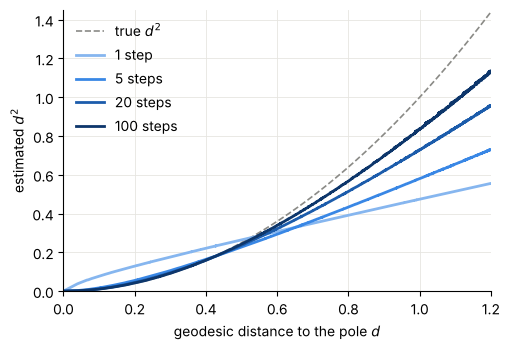

In [5]:
V, F = sphere(LEVEL)
L, a = laplacian(V, F)
pole = np.argmax(V[:, 2])
d = geodesic(V, V[pole])
order = np.argsort(d)[np.sort(d) <= 1.2]

fig, ax = axes()
ax.plot(d[order], d[order] ** 2, color=REF, lw=1.2, ls="--", label="true $d^2$")
for m, color in zip([1, 5, 20, 100], RAMP):
    est = implied_d2(heat_kernel(L, a, GAMMA, m), a, pole, GAMMA)
    ax.plot(d[order], est[order], color=color, lw=2, label=f"{m} step{'s' * (m > 1)}")
    print(f"{m:3d} substeps: implied d^2 at d = 1 is {est[np.argmin(abs(d - 1))]:.3f}")
ax.set(xlim=(0, 1.2), ylim=(0, 1.45), xlabel="geodesic distance to the pole $d$",
       ylabel="estimated $d^2$")
ax.legend(frameon=False, loc="upper left")
save(fig, "C_sphere_kernel.png")

## 5. Error vs mesh resolution and quality (Figure 5)

Mean relative error of $d_{\mathrm{est}}$ over $0.2 \le d \le 1$, for 5 random sources.

n =    642  regular     1 substeps: 21.5%
n =    642  regular    50 substeps: 14.2%
n =    642  perturbed   1 substeps: 22.7%
n =    642  perturbed  50 substeps: 15.8%
n =   2562  regular     1 substeps: 21.2%
n =   2562  regular    50 substeps: 8.7%
n =   2562  perturbed   1 substeps: 21.3%


n =   2562  perturbed  50 substeps: 9.6%
n =  10242  regular     1 substeps: 20.8%


n =  10242  regular    50 substeps: 5.4%
n =  10242  perturbed   1 substeps: 20.8%


n =  10242  perturbed  50 substeps: 6.0%


n =  40962  regular     1 substeps: 20.6%


n =  40962  regular    50 substeps: 4.0%


n =  40962  perturbed   1 substeps: 20.6%


n =  40962  perturbed  50 substeps: 4.3%


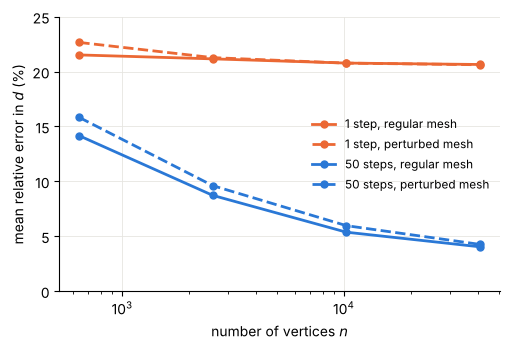

In [6]:
def relative_error(V, F, substeps, sources):
    L, a = laplacian(V, F)
    apply_K = heat_kernel(L, a, GAMMA, substeps)
    errors = []
    for s in sources:
        d = geodesic(V, V[s])
        d_est = np.sqrt(np.maximum(implied_d2(apply_K, a, s, GAMMA), 0))
        mask = (d >= 0.2) & (d <= 1.0)
        errors.append(np.mean(np.abs(d_est[mask] - d[mask]) / d[mask]))
    return 100 * np.mean(errors)


rng = np.random.default_rng(1)
sizes, results = [], {}
for level in [3, 4, 5, 6]:
    V, F = sphere(level)
    sizes.append(len(V))
    sources = rng.choice(len(V), 5, replace=False)
    for kind, X in [("regular", V), ("perturbed", perturb(V, F, 0.4))]:
        for m in [1, 50]:
            results.setdefault((kind, m), []).append(relative_error(X, F, m, sources))
            print(f"n = {len(V):6d}  {kind:9s}  {m:2d} substeps: {results[(kind, m)][-1]:.1f}%")

fig, ax = axes()
for m, color in [(1, ORANGE), (50, BLUE)]:
    for kind, ls in [("regular", "-"), ("perturbed", "--")]:
        ax.plot(sizes, results[(kind, m)], color=color, ls=ls, lw=2, marker="o", ms=5,
                label=f"{m} step{'s' * (m > 1)}, {kind} mesh")
ax.set(xscale="log", ylim=(0, 25), xlabel="number of vertices $n$",
       ylabel="mean relative error in $d$ (%)")
ax.legend(frameon=False, fontsize=8.5, loc="center right")
save(fig, "C_accuracy_vs_mesh.png")

## 6. Returned $W_2$ vs exact $W_2$

A bump at the north pole and the same bump rotated by $d$. The exact $W_2$ is computed with POT.

gamma = 0.01  dense kernel, exact distance  0.17 0.24 0.33 0.42 0.52 0.61 0.71 0.81 0.91 1.00


gamma = 0.01  heat kernel, 1 step           0.17 0.21 0.25 0.29 0.32 0.35 0.38 0.41 0.43 0.45


gamma = 0.01  heat kernel, 100 steps        0.17 0.23 0.30 0.37 0.43 0.50 0.56 0.61 0.67 0.72


gamma = 0.04  dense kernel, exact distance  0.32 0.36 0.42 0.50 0.58 0.67 0.76 0.85 0.94 1.04
gamma = 0.04  heat kernel, 1 step           0.32 0.37 0.42 0.47 0.51 0.55 0.59 0.62 0.65 0.68


gamma = 0.04  heat kernel, 100 steps        0.32 0.36 0.42 0.49 0.57 0.65 0.72 0.80 0.88 0.95


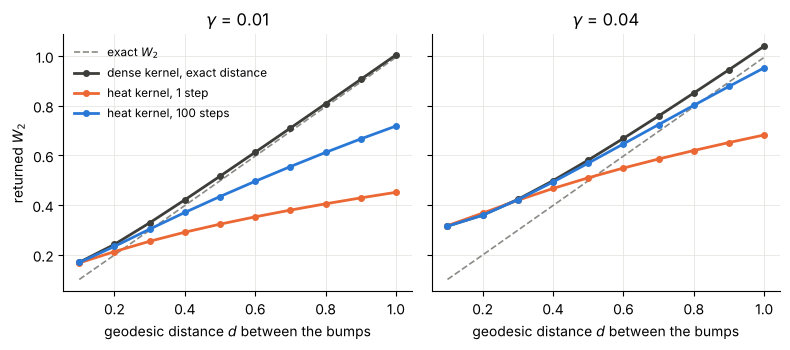

In [7]:
V, F = sphere(LEVEL)
L, a = laplacian(V, F)
distances = np.linspace(0.1, 1.0, 10)
exact = [exact_w2(V, a, bump(V, a, 0), bump(V, a, d)) for d in distances]

fig, axs = axes(1, 2, width=8, sharey=True)
for ax, gamma in zip(axs, [0.01, 0.04]):
    methods = [("dense kernel, exact distance", DARK, dense_kernel(V, a, gamma)),
               ("heat kernel, 1 step", ORANGE, heat_kernel(L, a, gamma, 1)),
               ("heat kernel, 100 steps", BLUE, heat_kernel(L, a, gamma, 100))]
    ax.plot(distances, exact, color=REF, lw=1.2, ls="--", label="exact $W_2$")
    for label, color, apply_K in methods:
        w2 = [np.sqrt(max(sinkhorn(bump(V, a, 0), bump(V, a, d), apply_K, a, gamma)[0], 0))
              for d in distances]
        ax.plot(distances, w2, color=color, lw=2, marker="o", ms=4, label=label)
        print(f"gamma = {gamma}  {label:29s}", " ".join(f"{x:.2f}" for x in w2))
    ax.set(title=f"$\\gamma$ = {gamma}", xlabel="geodesic distance $d$ between the bumps")
    del methods
axs[0].set_ylabel("returned $W_2$")
axs[0].legend(frameon=False, fontsize=8.5, loc="upper left")
save(fig, "C_distance_sweep.png")

## 7. Limitations

### Negative cotangent weights

Fraction of Diracs that diffuse into negative values, textbook vs `robust_laplacian`, and the consequence for Sinkhorn.

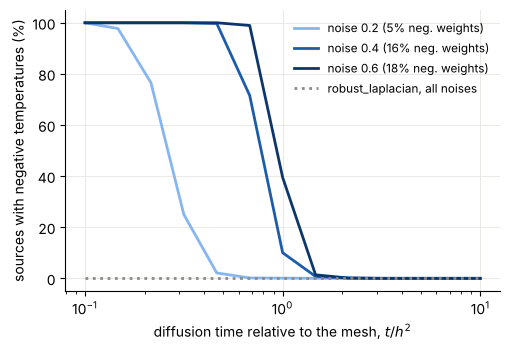

textbook Laplacian: W2^2 = nan, 385 negative scalings
robust   Laplacian: W2^2 = 0.1096, 0 negative scalings


In [8]:
def negative_sources(L, a, t):
    K = np.linalg.solve((sp.diags(a) + t * L).toarray(), np.diag(a))
    return 100 * (K < 0).any(axis=0).mean()


V0, F = sphere(4)
h = edge_length(V0, F)
ratios = np.logspace(-1, 1, 13)
fig, ax = axes()
robust = np.zeros_like(ratios)
for noise, color in zip([0.2, 0.4, 0.6], [RAMP[0], RAMP[2], RAMP[3]]):
    V = perturb(V0, F, noise)
    textbook = [negative_sources(*textbook_laplacian(V, F), r * h**2) for r in ratios]
    robust = np.maximum(robust, [negative_sources(*laplacian(V, F), r * h**2) for r in ratios])
    ax.plot(ratios, textbook, color=color, lw=2,
            label=f"noise {noise} ({100 * negative_weights(V, F):.0f}% neg. weights)")
ax.plot(ratios, robust, color=REF, lw=2, ls=":", label="robust_laplacian, all noises")
ax.set(xscale="log", xlabel="diffusion time relative to the mesh, $t / h^2$",
       ylabel="sources with negative temperatures (%)")
ax.legend(frameon=False, fontsize=8.5)
save(fig, "C_negative_weights.png")

V, gamma = perturb(V0, F, 0.4), 2 * h**2
for name, (L, a) in [("textbook", textbook_laplacian(V, F)), ("robust", laplacian(V, F))]:
    with np.errstate(all="ignore"):
        d2, v, w = sinkhorn(bump(V, a, 0), bump(V, a, 0.5), heat_kernel(L, a, gamma), a, gamma)
    print(f"{name:8s} Laplacian: W2^2 = {d2:.4f}, {(v < 0).sum() + (w < 0).sum()} negative scalings")

### Heat leaking between close parts

A strip folded into a hairpin: the tips are `gap` apart in space but about 2 apart along the surface.

gap 0.02: geodesic 2.03, mesh 1.84, point cloud 0.01


gap 0.04: geodesic 2.06, mesh 1.87, point cloud 0.00


gap 0.06: geodesic 2.09, mesh 1.90, point cloud 0.05


gap 0.08: geodesic 2.13, mesh 1.92, point cloud 0.10


gap 0.10: geodesic 2.16, mesh 1.95, point cloud 0.36


gap 0.12: geodesic 2.19, mesh 1.97, point cloud 1.96


... (4 outputs left out)

gap 0.22: geodesic 2.35, mesh 2.09, point cloud 2.08


gap 0.24: geodesic 2.38, mesh 2.12, point cloud 2.10


gap 0.26: geodesic 2.41, mesh 2.14, point cloud 2.13
gap 0.28: geodesic 2.44, mesh 2.16, point cloud 2.15


gap 0.30: geodesic 2.47, mesh 2.19, point cloud 2.17


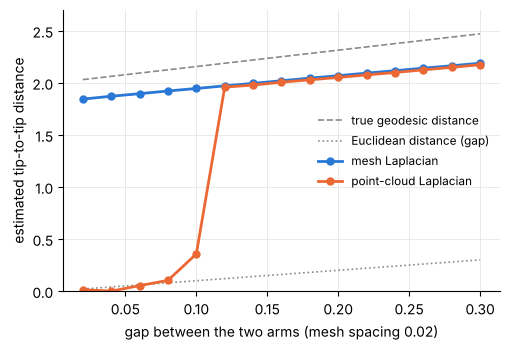

In [9]:
gamma, substeps, spacing = 0.05, 500, 0.02
gaps = np.linspace(0.02, 0.3, 15)


def tip_distance(L, a, tips):
    return np.sqrt(max(implied_d2(heat_kernel(L, a, gamma, substeps), a, tips[0], gamma)[tips[1]], 0))


mesh, cloud = [], []
for gap in gaps:
    V, F, tips = hairpin(gap, h=spacing)
    mesh.append(tip_distance(*laplacian(V, F), tips))
    L, M = robust_laplacian.point_cloud_laplacian(V)
    cloud.append(tip_distance(L, M.diagonal(), tips))
    print(f"gap {gap:.2f}: geodesic {2 + np.pi * gap / 2:.2f}, mesh {mesh[-1]:.2f}, "
          f"point cloud {cloud[-1]:.2f}")

fig, ax = axes()
ax.plot(gaps, 2 + np.pi * gaps / 2, color=REF, lw=1.2, ls="--", label="true geodesic distance")
ax.plot(gaps, gaps, color=REF, lw=1.2, ls=":", label="Euclidean distance (gap)")
ax.plot(gaps, mesh, color=BLUE, lw=2, marker="o", ms=5, label="mesh Laplacian")
ax.plot(gaps, cloud, color=ORANGE, lw=2, marker="o", ms=5, label="point-cloud Laplacian")
ax.set(ylim=(0, 2.7), xlabel=f"gap between the two arms (mesh spacing {spacing})",
       ylabel="estimated tip-to-tip distance")
ax.legend(frameon=False, fontsize=8.5, loc="center right")
save(fig, "C_leakage.png")